# ASSIGNMENT 2 — MÔ HÌNH XÁC SUẤT VÀ TỐI ƯU HOÁ (MAI391)
**Tập dữ liệu:** Iris Plants Database (UCI, tệp đã hiệu chỉnh `bezdekIris.data`, N = 150) — cùng tập dữ liệu với Assignment 1
**Phạm vi:** Chương 6 (Probability and Distributions), Chương 7 (Continuous Optimization)
**Nhóm:** ___

In [1]:

# Import các thư viện cần thiết
import importlib.util, subprocess, sys
REQUIRED = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import math
from fractions import Fraction
from pathlib import Path
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cấu hình hiển thị
np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Đường dẫn dữ liệu dùng chung cho cả 4 nhiệm vụ (tìm tệp bezdekIris.data ở các vị trí thường gặp)
DATA_PATH = next((Path(p) for p in ("bezdekIris.data", "data/bezdekIris.data", "iris/bezdekIris.data") if Path(p).exists()), None)
if DATA_PATH is None:   # không thấy tệp: tạo lại từ scikit-learn (cùng giá trị đã hiệu chỉnh)
    from sklearn.datasets import load_iris
    _ir = load_iris(as_frame=True)
    _tmp = _ir.frame.iloc[:, :4].copy()
    _tmp["species"] = ["Iris-" + _ir.target_names[t] for t in _ir.target]
    _tmp.to_csv("bezdekIris.data", header=False, index=False)
    DATA_PATH = Path("bezdekIris.data")
print("Dữ liệu:", DATA_PATH)

Dữ liệu: bezdekIris.data


---
# NHIỆM VỤ A — CHƯƠNG 6: PHÂN PHỐI RỜI RẠC VÀ BẢNG ĐỒNG THỜI

**MAI391 — Nhóm ___ | Thành viên phụ trách: ___**

**Dữ liệu:** Iris (Fisher 1936, UCI), tệp đã hiệu chỉnh `bezdekIris.data`, $N=150$ (cùng tập dữ liệu với Assignment 1).
$X$ = chiều dài cánh hoa (*petal length*, cm), $Y$ = chiều dài đài hoa (*sepal length*, cm).

Notebook gồm A1 → A4 theo đúng thứ tự đề bài. Phần **tính tay Cov (A3)** được viết đủ 5 bước ở dưới để đối chiếu với bản làm tay.

In [2]:
# === NHIỆM VỤ A: nạp dữ liệu ===
pd.set_option('display.precision', 4)
cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
df = pd.read_csv(DATA_PATH, header=None, names=cols + ['species'])
N = len(df)
print('N =', N, '| số đặc trưng số =', len(cols))
print('hệ số tương quan của hai đặc trưng gốc (petal_length, sepal_length): %.4f' % df['petal_length'].corr(df['sepal_length']))

N = 150 | số đặc trưng số = 4
hệ số tương quan của hai đặc trưng gốc (petal_length, sepal_length): 0.8718


### A1. Rời rạc hoá thành 3 mức và phân phối đồng thời
Phân vị 33% và 67%: mức 1 = thấp ($\le q_{33}$), mức 2 = trung bình ($(q_{33},q_{67}]$), mức 3 = cao ($>q_{67}$).

In [3]:
# === NHIỆM VỤ A1 ===
q = [0, 0.33, 0.67, 1]
levels = [1, 2, 3]
Xd = pd.qcut(df['petal_length'], q, labels=levels).astype(int)     # X: mức của chiều dài cánh hoa
Yd = pd.qcut(df['sepal_length'], q, labels=levels).astype(int)     # Y: mức của chiều dài đài hoa
print('ngưỡng X (cm):', np.quantile(df['petal_length'], [0.33, 0.67]))
print('ngưỡng Y (cm):', np.quantile(df['sepal_length'], [0.33, 0.67]))

counts = pd.crosstab(Xd, Yd, margins=True, margins_name='tổng')    # bảng tần suất 3x3 kèm lề
counts.index.name, counts.columns.name = 'x \\ y', None
display(counts)

n = pd.crosstab(Xd, Yd).to_numpy()          # ma trận số lượng n(x,y), cỡ 3x3
p = n / N                                   # phân phối đồng thời thực nghiệm p(x,y)
display(pd.DataFrame(p, index=levels, columns=levels))
print('tổng p(x,y) =', p.sum(), '| mọi phần tử >= 0:', bool((p >= 0).all()))
assert abs(p.sum() - 1) < 1e-12 and n.sum() == N

ngưỡng X (cm): [2.087 4.9  ]
ngưỡng Y (cm): [5.4 6.3]


,1,2,3,tổng
x \ y,,,,
1,45,5,0,50
2,7,37,10,54
3,0,14,32,46
tổng,52,56,42,150


,1,2,3
1,0.3000,0.0333,0.0000
2,0.0467,0.2467,0.0667
3,0.0000,0.0933,0.2133


tổng p(x,y) = 1.0 | mọi phần tử >= 0: True


### A2. Phân phối biên và xác suất có điều kiện

In [4]:
# === NHIỆM VỤ A2 ===
pX, pY = p.sum(axis=1), p.sum(axis=0)         # quy tắc tổng: tổng hàng, tổng cột
tab = pd.DataFrame(p, index=['x=1 (thấp)', 'x=2 (trung bình)', 'x=3 (cao)'],
                   columns=['y=1 (thấp)', 'y=2 (trung bình)', 'y=3 (cao)'])
tab['p_X(x)'] = pX
tab.loc['p_Y(y)'] = list(pY) + [pX.sum()]
display(tab)

,y=1 (thấp),y=2 (trung bình),y=3 (cao),p_X(x)
x=1 (thấp),0.3000,0.0333,0.0000,0.3333
x=2 (trung bình),0.0467,0.2467,0.0667,0.3600
x=3 (cao),0.0000,0.0933,0.2133,0.3067
p_Y(y),0.3467,0.3733,0.2800,1.0000


In [5]:
# p(y | x=2): một HÀNG của bảng, chia cho p_X(2)        p(x | y=2): một CỘT của bảng, chia cho p_Y(2)
p_y_given_x2 = p[1, :] / pX[1]
p_x_given_y2 = p[:, 1] / pY[1]
print('p(y | x=2) =', p_y_given_x2, '| tổng =', p_y_given_x2.sum())
print('p(x | y=2) =', p_x_given_y2, '| tổng =', p_x_given_y2.sum())
print('cùng ô đồng thời p(2,2) = %.4f nhưng chia cho p_X(2)=%.4f và p_Y(2)=%.4f -> hai kết quả khác nhau' % (p[1,1], pX[1], pY[1]))

# liên hệ bằng công thức Bayes: p(x|y) = p(y|x) p_X(x) / p_Y(y)
bayes = p_y_given_x2[1] * pX[1] / pY[1]
print('Bayes: p(x=2|y=2) = %.4f  (khớp với %.4f: %s)' % (bayes, p_x_given_y2[1], np.isclose(bayes, p_x_given_y2[1])))

# toàn bộ hai ma trận điều kiện (mỗi hàng của P(Y|X) và mỗi cột của P(X|Y) có tổng bằng 1)
P_y_given_x = p / pX[:, None]
P_x_given_y = p / pY[None, :]
display(pd.DataFrame(P_y_given_x, index=['x=1','x=2','x=3'], columns=['y=1','y=2','y=3']).rename_axis('P(y|x)'))
display(pd.DataFrame(P_x_given_y, index=['x=1','x=2','x=3'], columns=['y=1','y=2','y=3']).rename_axis('P(x|y)'))

p(y | x=2) = [0.12962963 0.68518519 0.18518519] | tổng = 1.0
p(x | y=2) = [0.08928571 0.66071429 0.25      ] | tổng = 1.0
cùng ô đồng thời p(2,2) = 0.2467 nhưng chia cho p_X(2)=0.3600 và p_Y(2)=0.3733 -> hai kết quả khác nhau
Bayes: p(x=2|y=2) = 0.6607  (khớp với 0.6607: True)


,y=1,y=2,y=3
P(y|x),,,
x=1,0.9000,0.1000,0.0000
x=2,0.1296,0.6852,0.1852
x=3,0.0000,0.3043,0.6957


,y=1,y=2,y=3
P(x|y),,,
x=1,0.8654,0.0893,0.0000
x=2,0.1346,0.6607,0.2381
x=3,0.0000,0.2500,0.7619


### A3. Kỳ vọng, hiệp phương sai, tương quan từ bảng
Các mức được mã hoá $x,y\in\{1,2,3\}$ (mã thứ bậc, không thứ nguyên). Mẫu số là $N$ (quy ước của môn học).
Dưới đây là **5 bước** như bản làm tay: tổng hàng → tổng cột → $\mathbb E[X],\mathbb E[Y]$ → $\mathbb E[XY]$ từng ô → thay vào công thức.

In [6]:
# === NHIỆM VỤ A3 ===
v = np.array([1, 2, 3])
# Bước 1, 2: tổng hàng và tổng cột (số lượng)
row_tot, col_tot = n.sum(axis=1), n.sum(axis=0)
print('Bước 1 - tổng hàng n_x. =', row_tot, '| Bước 2 - tổng cột n_.y =', col_tot)
# Bước 3: E[X], E[Y]  (dùng phân số để so với bản tính tay)
EX = Fraction(int(v @ row_tot), N); EY = Fraction(int(v @ col_tot), N)
print('Bước 3 - E[X] = %s = %.5f | E[Y] = %s = %.5f' % (EX, EX, EY, EY))
# Bước 4: E[XY] = tổng x*y*n(x,y) / N, từng ô
cell = np.array([[v[i] * v[j] * n[i, j] for j in range(3)] for i in range(3)])
display(pd.DataFrame(cell, index=[1, 2, 3], columns=[1, 2, 3]).rename_axis('x*y*n(x,y)'))
EXY = Fraction(int(cell.sum()), N)
print('Bước 4 - tổng chín ô = %d -> E[XY] = %s = %.5f' % (cell.sum(), EXY, EXY))
# Bước 5: Cov = E[XY] - E[X]E[Y]
cov = EXY - EX * EY
print('Bước 5 - Cov[X,Y] = %s = %.5f' % (cov, cov))
# tương quan
VX = Fraction(int((v**2) @ row_tot), N) - EX**2
VY = Fraction(int((v**2) @ col_tot), N) - EY**2
corr = float(cov) / np.sqrt(float(VX) * float(VY))
print('V[X] = %.5f | V[Y] = %.5f | corr[X,Y] = %.4f' % (VX, VY, corr))

Bước 1 - tổng hàng n_x. = [50 54 46] | Bước 2 - tổng cột n_.y = [52 56 42]
Bước 3 - E[X] = 148/75 = 1.97333 | E[Y] = 29/15 = 1.93333


,1,2,3
"x*y*n(x,y)",,,
1,45,10,0
2,14,148,60
3,0,84,288


Bước 4 - tổng chín ô = 649 -> E[XY] = 649/150 = 4.32667
Bước 5 - Cov[X,Y] = 1151/2250 = 0.51156
V[X] = 0.63929 | V[Y] = 0.62222 | corr[X,Y] = 0.8111


In [7]:
# Đối chiếu bằng numpy (bias=True: mẫu số N, khác mặc định N-1 của thư viện)
print('numpy.cov  :', np.cov(Xd, Yd, bias=True)[0, 1])
print('numpy.corr :', np.corrcoef(Xd, Yd)[0, 1])
assert np.isclose(float(cov), np.cov(Xd, Yd, bias=True)[0, 1]) and np.isclose(corr, np.corrcoef(Xd, Yd)[0, 1])

numpy.cov  : 0.5115555555555543
numpy.corr : 0.8110945226337254


### A4. Kiểm tra tính độc lập
$X\perp Y \iff p(x,y)=p_X(x)\,p_Y(y)$ với **mọi** cặp $(x,y)$; chỉ cần một ô vi phạm là đủ kết luận phụ thuộc.

In [8]:
# === NHIỆM VỤ A4 ===
prod = np.outer(pX, pY)                                  # p_X(x) * p_Y(y)
diff = p - prod
display(pd.DataFrame(prod, index=[1,2,3], columns=[1,2,3]).rename_axis('p_X(x) p_Y(y)'))
display(pd.DataFrame(diff, index=[1,2,3], columns=[1,2,3]).rename_axis('p(x,y) - p_X p_Y'))
bad = [(i+1, j+1) for i in range(3) for j in range(3) if not np.isclose(p[i, j], prod[i, j])]
print('số ô vi phạm:', len(bad), 'trên 9 ô ->', bad)
print('độc lập?', np.allclose(p, prod))
i, j = 0, 2
print('Ví dụ ô (1,3): p(1,3) = %.4f nhưng p_X(1) p_Y(3) = %.4f x %.4f = %.4f != 0' % (p[i, j], pX[i], pY[j], prod[i, j]))
# độc lập => Cov = 0; ở đây Cov != 0 nên cũng suy ra phụ thuộc
print('Cov =', float(cov), '!= 0  =>  phụ thuộc (phù hợp)')

,1,2,3
p_X(x) p_Y(y),,,
1,0.1156,0.1244,0.0933
2,0.1248,0.1344,0.1008
3,0.1063,0.1145,0.0859


,1,2,3
"p(x,y) - p_X p_Y",,,
1,0.1844,-0.0911,-0.0933
2,-0.0781,0.1123,-0.0341
3,-0.1063,-0.0212,0.1275


số ô vi phạm: 9 trên 9 ô -> [(1, 1), (1, 2), (1, 3), (2, 1), (2, 2), (2, 3), (3, 1), (3, 2), (3, 3)]
độc lập? False
Ví dụ ô (1,3): p(1,3) = 0.0000 nhưng p_X(1) p_Y(3) = 0.3333 x 0.2800 = 0.0933 != 0
Cov = 0.5115555555555555 != 0  =>  phụ thuộc (phù hợp)


**Cov = 0 không kéo theo độc lập.** Ví dụ chuẩn: $X$ đều trên $\{-1,0,1\}$, $Y=X^2$. Dữ liệu của nhóm có $\mathrm{Cov}\neq0$ nên không gặp trường hợp này; ví dụ dưới đây chỉ để minh hoạ.

In [9]:
xs = np.array([-1, 0, 1]); ys = np.array([0, 1])
pj = np.zeros((3, 2))                       # p(x,y) với Y = X^2, X đều
for a, xv in enumerate(xs): pj[a, int(xv**2)] = 1 / 3
px_, py_ = pj.sum(1), pj.sum(0)
EX_ = xs @ px_; EY_ = ys @ py_
EXY_ = sum(xs[a] * ys[b] * pj[a, b] for a in range(3) for b in range(2))
print('Cov[X,Y] =', EXY_ - EX_ * EY_, '(bằng 0)')
print('độc lập?', np.allclose(pj, np.outer(px_, py_)), '| p(x=0,y=1) = %.4f, p_X(0) p_Y(1) = %.4f' % (pj[1, 1], px_[1] * py_[1]))

Cov[X,Y] = 0.0 (bằng 0)
độc lập? False | p(x=0,y=1) = 0.0000, p_X(0) p_Y(1) = 0.2222


### Tóm tắt Nhiệm vụ A
* A1: bảng đồng thời 3×3 có tổng bằng 1.
* A2: $p(y\mid x=2)\neq p(x\mid y=2)$ vì chia cho hai phân phối biên khác nhau; hai đại lượng liên hệ qua công thức Bayes.
* A3: $\mathrm{Cov}[X,Y]=11510/22500\approx0.5116$, $\mathrm{corr}\approx0.811$.
* A4: không độc lập (9/9 ô vi phạm); Cov = 0 không đủ để kết luận độc lập.

**Khai báo công cụ:** soạn thảo với sự hỗ trợ của AI (Claude). Phần tính tay Cov (A3) phải do thành viên phụ trách tự làm lại và giải thích được.

---
# NHIỆM VỤ B — CHƯƠNG 6: PHÂN PHỐI LIÊN TỤC VÀ GAUSS

**Tập dữ liệu:** cùng dữ liệu Iris như Assignment 1 (`data/bezdekIris.data`, 150 mẫu, mọi số đo đều tính bằng **cm**).
**Các nhiệm vụ:** B1 vectơ kỳ vọng và ma trận hiệp phương sai · B2 phân phối biên Gauss · B3 phân phối có điều kiện Gauss (làm tay) · B4 biểu đồ phân tán + đường đồng mức mật độ · B5 hỗn hợp hai phân phối Gauss (làm tay).

**Quy ước dùng xuyên suốt notebook (theo yêu cầu của môn học):** hiệp phương sai mẫu chia cho **N** (không phải N−1). Mọi đại lượng đều có đơn vị: $\mu$ tính bằng cm, $\Sigma$ tính bằng cm², hệ số tương quan không có thứ nguyên.

| Bước | Nội dung |
|---|---|
| 0 | Thiết lập, dữ liệu, chọn hai đặc trưng $X$ và $Y$ |
| B1 | $\mu$ và $\Sigma$ với công thức $1/N$ |
| B2 | Phân phối biên của $Y$ đọc trực tiếp từ khối con của $\Sigma$ |
| B3 | Phân phối có điều kiện $p(x\mid y=y_0)$, $y_0$ = phân vị 75 của $Y$, làm tay, sau đó kiểm tra bằng bốn cách |
| B4 | Biểu đồ phân tán (scatter plot) + đường đồng mức Gauss (contour), mức độ phù hợp của giả thiết Gauss |
| B5 | Hỗn hợp hai phân phối Gauss 1 chiều (mixture): $E[X]$, $V[X]$, luật phương sai toàn phần (law of total variance) |


In [10]:
# === NHIỆM VỤ B: cấu hình & nạp dữ liệu ===
np.set_printoptions(precision=6, suppress=True, linewidth=120)
pd.set_option("display.precision", 6)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

FEATURES = ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]
DATA_FILE = DATA_PATH
if DATA_FILE.exists():
    df = pd.read_csv(DATA_FILE, header=None, names=FEATURES + ["species"]).dropna()
else:  # dự phòng: scikit-learn có sẵn các giá trị Iris đã hiệu chỉnh
    from sklearn.datasets import load_iris
    ir = load_iris(as_frame=True)
    df = ir.frame.iloc[:, :4].copy(); df.columns = FEATURES
    df["species"] = ir.target_names[ir.target]
print("kích thước dữ liệu:", df[FEATURES].shape, "| các loài:", df["species"].unique())


kích thước dữ liệu: (150, 4) | các loài: <StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str


### 0.1 Chọn hai đặc trưng $X$ và $Y$

Đề bài khuyến nghị chọn một cặp có tương quan rõ rệt (một cặp gần như độc lập sẽ làm B3 trở nên tầm thường). Hệ số tương quan (correlation) của dữ liệu gốc (không thứ nguyên):


In [11]:
corr = df[FEATURES].corr()
print(corr.round(3))


                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)              1.000            -0.118              0.872   
sepal width (cm)              -0.118             1.000             -0.428   
petal length (cm)              0.872            -0.428              1.000   
petal width (cm)               0.818            -0.366              0.963   

                   petal width (cm)  
sepal length (cm)             0.818  
sepal width (cm)             -0.366  
petal length (cm)             0.963  
petal width (cm)              1.000  


In [12]:
# >>> Cặp đặc trưng được chọn. Nếu nhóm (hoặc Nhiệm vụ A của assignment này) dùng cặp khác, CHỈ đổi hai dòng này. <<<
X_NAME, Y_NAME = "sepal length (cm)", "petal length (cm)"

x = df[X_NAME].to_numpy(float)
y = df[Y_NAME].to_numpy(float)
D = np.column_stack([x, y])           # ma trận dữ liệu N x 2, các cột (X, Y), đơn vị cm
N = len(D)
print(f"X = {X_NAME},  Y = {Y_NAME},  N = {N},  corr(X,Y) = {np.corrcoef(x, y)[0, 1]:.4f}")


X = sepal length (cm),  Y = petal length (cm),  N = 150,  corr(X,Y) = 0.8718


**Vì sao chọn cặp này:** chiều dài đài hoa (sepal length) và chiều dài cánh hoa (petal length) có tương quan dương mạnh (khoảng 0.87), nên điều kiện hoá theo $Y$ sẽ làm phân phối của $X$ thay đổi thấy rõ (B3). Cặp này cũng được biết là tạo thành các cụm (các loài), khiến phần bàn về độ phù hợp của mô hình Gauss ở B4 trở nên thú vị.


### B1. Vectơ kỳ vọng $\mu$ và ma trận hiệp phương sai $\Sigma$ (mean vector, covariance matrix)

**Đề bài.** Ước lượng $\mu$ và $\Sigma$ bằng công thức mẫu $\Sigma=\frac1N\sum_n(x_n-\bar x)(x_n-\bar x)^\top$.

**Lời giải.** 
$$\mu=\frac1N\sum_{n=1}^N x_n\in\mathbb R^2,\qquad
\Sigma=\begin{pmatrix}\Sigma_{xx}&\Sigma_{xy}\\ \Sigma_{yx}&\Sigma_{yy}\end{pmatrix}=\frac1N\,D_c^\top D_c,$$
trong đó $D_c$ là ma trận dữ liệu đã trung tâm hoá (centred) cỡ $N\times2$. $\Sigma_{xx},\Sigma_{yy}$ là các phương sai (variance) và $\Sigma_{xy}=\Sigma_{yx}$ là hiệp phương sai (covariance).


In [13]:
# === NHIỆM VỤ B1 ===
mu = D.mean(axis=0)                         # (mu_x, mu_y) tính bằng cm
Dc = D - mu
Sigma = Dc.T @ Dc / N                       # mẫu số N (quy ước môn học), đơn vị cm^2

print("mu    =", mu, " (cm)")
print("Sigma =\n", Sigma, "\n (cm^2)")

# kiểm tra chéo
print("\nkhớp với np.cov(..., bias=True) [mẫu số N]   :", np.allclose(Sigma, np.cov(D.T, bias=True)))
Sigma_unbiased = np.cov(D.T)                # mặc định của numpy: mẫu số N-1
print("np.cov mặc định dùng N-1; tỉ số Sigma_N / Sigma_(N-1) =", (Sigma / Sigma_unbiased)[0, 0].round(6),
      "= (N-1)/N =", (N - 1) / N)
Sxx, Sxy, Syy = Sigma[0, 0], Sigma[0, 1], Sigma[1, 1]
rho = Sxy / math.sqrt(Sxx * Syy)
print(f"\nSigma_xx = {Sxx:.4f} cm^2,  Sigma_yy = {Syy:.4f} cm^2,  Sigma_xy = {Sxy:.4f} cm^2")
print(f"độ lệch chuẩn(X) = {math.sqrt(Sxx):.4f} cm,  độ lệch chuẩn(Y) = {math.sqrt(Syy):.4f} cm,  hệ số tương quan rho = {rho:.4f} (không thứ nguyên)")
print("Sigma đối xứng:", np.allclose(Sigma, Sigma.T), "| det(Sigma) =", np.linalg.det(Sigma).round(6),
      "| các giá trị riêng:", np.linalg.eigvalsh(Sigma), "(đều > 0 -> ma trận hiệp phương sai hợp lệ)")


mu    = [5.843333 3.758   ]  (cm)
Sigma =
 [[0.681122 1.26582 ]
 [1.26582  3.095503]] 
 (cm^2)

khớp với np.cov(..., bias=True) [mẫu số N]   : True
np.cov mặc định dùng N-1; tỉ số Sigma_N / Sigma_(N-1) = 0.993333 = (N-1)/N = 0.9933333333333333

Sigma_xx = 0.6811 cm^2,  Sigma_yy = 3.0955 cm^2,  Sigma_xy = 1.2658 cm^2
độ lệch chuẩn(X) = 0.8253 cm,  độ lệch chuẩn(Y) = 1.7594 cm,  hệ số tương quan rho = 0.8718 (không thứ nguyên)
Sigma đối xứng: True | det(Sigma) = 0.506115 | các giá trị riêng: [0.139139 3.637486] (đều > 0 -> ma trận hiệp phương sai hợp lệ)


**Nhận xét.**
* Quy ước là **mẫu số $N$**, đúng theo yêu cầu của môn học. `np.cov` mặc định dùng $N-1$, nên ta truyền `bias=True` (hoặc tính tay như trên). Hai phiên bản khác nhau một hệ số $(N-1)/N\approx0.9933$; hệ số này không làm đổi các hệ số tương quan hay bất kỳ kết luận nào, nhưng làm đổi chữ số thập phân thứ 3–4 của $\Sigma$, vì vậy hãy nêu rõ quy ước trong báo cáo.
* $\Sigma$ đối xứng và xác định dương (positive definite; cả hai giá trị riêng đều dương), nên $\mathcal N(\mu,\Sigma)$ là một hàm mật độ hợp lệ.


### B2. Phân phối biên của $Y$ (marginal distribution)

**Đề bài.** Giả sử $(X,Y)\sim\mathcal N(\mu,\Sigma)$. Viết phân phối biên của $Y$ bằng cách đọc khối con tương ứng, và giải thích vì sao không cần tính tích phân.

**Lời giải.**
$$p(y)=\int p(x,y)\,dx=\mathcal N\!\big(y\mid\mu_y,\Sigma_{yy}\big).$$
Phân phối biên của một phân phối Gauss nhiều chiều vẫn là Gauss; kỳ vọng của nó là phần tử tương ứng của $\mu$ và phương sai là khối đường chéo tương ứng của $\Sigma$.

**Vì sao không cần tích phân.** Lấy phân phối biên của Gauss là một *tính chất dạng đóng* (closed-form property; Chương 6): khi hoàn thiện bình phương của số mũ theo $x$, tích phân theo $x$ là một tích phân Gauss chỉ sinh ra một hằng số, còn phần số mũ còn lại theo $y$ có đúng kỳ vọng $\mu_y$ và phương sai $\Sigma_{yy}$. Tương đương, $Y=(0\ \ 1)\,(X,Y)^\top$ là một ánh xạ tuyến tính của vectơ Gauss, nên nó là Gauss với kỳ vọng $(0\ \ 1)\mu=\mu_y$ và phương sai $(0\ \ 1)\Sigma(0\ \ 1)^\top=\Sigma_{yy}$.


In [14]:
# === NHIỆM VỤ B2 ===
mu_x, mu_y = mu
print(f"p(y) = N(y | mu_y = {mu_y:.4f} cm,  Sigma_yy = {Syy:.4f} cm^2)")

# --- kiểm tra bằng phương pháp số (chính là tích phân mà ta KHÔNG cần tính) ---
def mvn_pdf(points, mean, cov):
    """Mật độ của N(mean, cov) tại các hàng của `points`."""
    diff = np.atleast_2d(points) - mean
    inv = np.linalg.inv(cov)
    expo = -0.5 * np.einsum("ni,ij,nj->n", diff, inv, diff)
    return np.exp(expo) / (2 * np.pi * math.sqrt(np.linalg.det(cov)))

def norm_pdf(t, m, var):
    return np.exp(-0.5 * (t - m) ** 2 / var) / math.sqrt(2 * np.pi * var)

def trapezoid(f, t, axis=-1):
    t = np.asarray(t); dt = np.diff(t)
    return np.sum(0.5 * (np.take(f, range(1, len(t)), axis) + np.take(f, range(0, len(t) - 1), axis)) * dt, axis=axis)

xs = np.linspace(mu_x - 10 * math.sqrt(Sxx), mu_x + 10 * math.sqrt(Sxx), 4001)
ys_test = np.linspace(mu_y - 3 * math.sqrt(Syy), mu_y + 3 * math.sqrt(Syy), 7)
rows = []
for yv in ys_test:
    joint_slice = mvn_pdf(np.column_stack([xs, np.full_like(xs, yv)]), mu, Sigma)
    numeric = trapezoid(joint_slice, xs)               # tích phân thô theo x
    formula = norm_pdf(yv, mu_y, Syy)                  # đọc trực tiếp từ khối Sigma_yy
    rows.append({"y (cm)": yv, "tích phân số của p(x,y) dx": numeric, "N(y | mu_y, Sigma_yy)": formula,
                 "sai khác tuyệt đối": abs(numeric - formula)})
print(pd.DataFrame(rows).round(8).to_string(index=False))

# --- kiểm tra Monte Carlo ---
rng = np.random.default_rng(0)
samp = rng.multivariate_normal(mu, Sigma, size=500_000)
print(f"\nMonte Carlo (500k mẫu): trung bình(Y) = {samp[:, 1].mean():.4f} (mục tiêu {mu_y:.4f}), "
      f"phương sai(Y) = {samp[:, 1].var():.4f} (mục tiêu {Syy:.4f})")


p(y) = N(y | mu_y = 3.7580 cm,  Sigma_yy = 3.0955 cm^2)
   y (cm)  tích phân số của p(x,y) dx  N(y | mu_y, Sigma_yy)  sai khác tuyệt đối
-1.520212                    0.002519               0.002519                 0.0
 0.239192                    0.030687               0.030687                 0.0
 1.998596                    0.137530               0.137530                 0.0
 3.758000                    0.226749               0.226749                 0.0
 5.517404                    0.137530               0.137530                 0.0
 7.276808                    0.030687               0.030687                 0.0
 9.036212                    0.002519               0.002519                 0.0

Monte Carlo (500k mẫu): trung bình(Y) = 3.7551 (mục tiêu 3.7580), phương sai(Y) = 3.1021 (mục tiêu 3.0955)


**Nhận xét.** Tích phân tính bằng phương pháp số (brute-force) khớp với đáp án một dòng đến độ chính xác số học. Phân phối biên của $X$ cũng tương tự là $\mathcal N(\mu_x,\Sigma_{xx})$. Lưu ý chiều ngược lại **không** đúng: biết cả hai phân phối biên vẫn không xác định được phân phối đồng thời (tương quan $\Sigma_{xy}$ bị mất).


### B3. Phân phối có điều kiện $p(x\mid y=y_0)$ (conditional distribution) — làm tay

**Đề bài.** Gọi $y_0$ là phân vị 75 của $Y$. Tính $p(x\mid y=y_0)$, nêu kỳ vọng và phương sai có điều kiện, và kiểm tra rằng phương sai có điều kiện nhỏ hơn $\Sigma_{xx}$.

**Công thức (viết trước, rồi mới thay số).** Với $\mu=(\mu_x,\mu_y)^\top$ và $\Sigma=\begin{pmatrix}\Sigma_{xx}&\Sigma_{xy}\\\Sigma_{yx}&\Sigma_{yy}\end{pmatrix}$:
$$p(x\mid y_0)=\mathcal N\!\big(x\mid\mu_{x|y},\,\Sigma_{x|y}\big),\qquad
\mu_{x|y}=\mu_x+\Sigma_{xy}\Sigma_{yy}^{-1}(y_0-\mu_y),\qquad
\Sigma_{x|y}=\Sigma_{xx}-\Sigma_{xy}\Sigma_{yy}^{-1}\Sigma_{yx}.$$
Vì $\Sigma_{xy}\Sigma_{yy}^{-1}\Sigma_{yx}=\Sigma_{xy}^2/\Sigma_{yy}\ge0$ (một bình phương chia cho một số dương), nên $\Sigma_{x|y}\le\Sigma_{xx}$, và $\Sigma_{x|y}=\Sigma_{xx}(1-\rho^2)$ với $\rho$ là hệ số tương quan. Nếu phép kiểm tra $\Sigma_{x|y}<\Sigma_{xx}$ không đạt thì chỉ số các khối đã bị hoán đổi.

**Quy ước phân vị.** $y_0$ = phân vị 75 của các giá trị $Y$ quan sát được (`numpy.percentile`, nội suy tuyến tính).

Ô lệnh bên dưới đi theo đúng các công thức với **số học trên giấy làm tròn 4 chữ số thập phân** (không dùng `inv`, không dùng hàm điều kiện hoá có sẵn).


In [15]:
# === NHIỆM VỤ B3 ===
DP = 4
R = lambda t: round(float(t), DP)

y0 = float(np.percentile(y, 75))
print(f"y0 = phân vị 75 của Y = {y0} cm")

# các số lấy từ B1, làm tròn như khi tính trên giấy
mx, my = R(mu_x), R(mu_y)
sxx, sxy, syy = R(Sxx), R(Sxy), R(Syy)
y0_p = R(y0)
print(f"mu_x = {mx}, mu_y = {my}, Sigma_xx = {sxx}, Sigma_xy = {sxy}, Sigma_yy = {syy}, y0 = {y0_p}")

# Bước 1: hệ số khuếch đại (gain)  K = Sigma_xy / Sigma_yy   ("nghịch đảo" cỡ 1x1 chỉ là một phép chia)
K = R(sxy / syy)
# Bước 2: kỳ vọng có điều kiện
dev = R(y0_p - my)
shift = R(K * dev)
mu_cond_hand = R(mx + shift)
# Bước 3: phương sai có điều kiện
reduction = R(K * sxy)                  # Sigma_xy * Sigma_yy^-1 * Sigma_yx = K * Sigma_xy
var_cond_hand = R(sxx - reduction)
# Bước 4: kiểm tra hợp lý
rho2_hand = R(R(sxy * sxy) / R(sxx * syy))

print(f"\nbước 1  K = Sigma_xy / Sigma_yy = {sxy} / {syy} = {K}")
print(f"bước 2  mu_(x|y) = mu_x + K (y0 - mu_y) = {mx} + {K} * ({y0_p} - {my}) = {mx} + {K} * {dev} = {mx} + {shift} = {mu_cond_hand} cm")
print(f"bước 3  Sigma_(x|y) = Sigma_xx - K * Sigma_xy = {sxx} - {K} * {sxy} = {sxx} - {reduction} = {var_cond_hand} cm^2")
print(f"bước 4  rho^2 = Sigma_xy^2 / (Sigma_xx Sigma_yy) = {rho2_hand};  Sigma_xx (1 - rho^2) = {R(sxx * (1 - rho2_hand))}  (phải bằng bước 3)")
print(f"\nKIỂM TRA  Sigma_(x|y) = {var_cond_hand} < Sigma_xx = {sxx}  ->  {var_cond_hand < sxx}")
print(f"độ lệch chuẩn có điều kiện = {R(math.sqrt(var_cond_hand))} cm  (độ lệch chuẩn biên của X = {R(math.sqrt(sxx))} cm)")
print(f"\nKẾT QUẢ  p(x | y = {y0_p}) = N( {mu_cond_hand} cm , {var_cond_hand} cm^2 )")


y0 = phân vị 75 của Y = 5.1 cm
mu_x = 5.8433, mu_y = 3.758, Sigma_xx = 0.6811, Sigma_xy = 1.2658, Sigma_yy = 3.0955, y0 = 5.1

bước 1  K = Sigma_xy / Sigma_yy = 1.2658 / 3.0955 = 0.4089
bước 2  mu_(x|y) = mu_x + K (y0 - mu_y) = 5.8433 + 0.4089 * (5.1 - 3.758) = 5.8433 + 0.4089 * 1.342 = 5.8433 + 0.5487 = 6.392 cm
bước 3  Sigma_(x|y) = Sigma_xx - K * Sigma_xy = 0.6811 - 0.4089 * 1.2658 = 0.6811 - 0.5176 = 0.1635 cm^2
bước 4  rho^2 = Sigma_xy^2 / (Sigma_xx Sigma_yy) = 0.7599;  Sigma_xx (1 - rho^2) = 0.1635  (phải bằng bước 3)

KIỂM TRA  Sigma_(x|y) = 0.1635 < Sigma_xx = 0.6811  ->  True
độ lệch chuẩn có điều kiện = 0.4044 cm  (độ lệch chuẩn biên của X = 0.8253 cm)

KẾT QUẢ  p(x | y = 5.1) = N( 6.392 cm , 0.1635 cm^2 )


#### Kiểm tra B3 bằng code (bốn cách độc lập)
1. công thức chính xác với số thực dấu phẩy động;
2. dạng **ma trận độ chính xác** (precision matrix): $\Sigma_{x|y}=(\Lambda_{xx})^{-1}$ và $\mu_{x|y}=\mu_x-\Lambda_{xx}^{-1}\Lambda_{xy}(y_0-\mu_y)$ với $\Lambda=\Sigma^{-1}$ (một đường đi khác đến cùng đáp án);
3. cắt **mật độ đồng thời** tại $y=y_0$, chuẩn hoá bằng phương pháp số theo $x$, rồi tính kỳ vọng và phương sai của nó;
4. **Monte Carlo**: lấy mẫu từ phân phối Gauss và giữ lại các điểm có $Y$ rất gần $y_0$.


In [16]:
# 1. công thức chính xác
mu_cond = mu_x + Sxy / Syy * (y0 - mu_y)
var_cond = Sxx - Sxy ** 2 / Syy

# 2. đi qua ma trận độ chính xác (precision matrix)
Lam = np.linalg.inv(Sigma)
var_cond_prec = 1.0 / Lam[0, 0]
mu_cond_prec = mu_x - Lam[0, 1] / Lam[0, 0] * (y0 - mu_y)

# 3. lát cắt của mật độ đồng thời, chuẩn hoá theo x
xs = np.linspace(mu_x - 10 * math.sqrt(Sxx), mu_x + 10 * math.sqrt(Sxx), 20001)
slice_ = mvn_pdf(np.column_stack([xs, np.full_like(xs, y0)]), mu, Sigma)
slice_ /= trapezoid(slice_, xs)                              # chia cho p(y0): hằng số chuẩn hoá
mu_cond_slice = trapezoid(xs * slice_, xs)
var_cond_slice = trapezoid((xs - mu_cond_slice) ** 2 * slice_, xs)
pdf_gap = np.abs(slice_ - norm_pdf(xs, mu_cond, var_cond)).max()

# 4. điều kiện hoá bằng Monte Carlo (cửa sổ |Y - y0| < 0.02)
big = np.random.default_rng(1).multivariate_normal(mu, Sigma, size=4_000_000)
near = big[np.abs(big[:, 1] - y0) < 0.02, 0]

res = pd.DataFrame({
    "kỳ vọng có điều kiện (cm)":    [mu_cond_hand, mu_cond, mu_cond_prec, mu_cond_slice, near.mean()],
    "phương sai có điều kiện (cm^2)": [var_cond_hand, var_cond, var_cond_prec, var_cond_slice, near.var()],
}, index=["làm tay (4 chữ số TP)", "1. công thức chính xác", "2. ma trận độ chính xác", "3. lát cắt chuẩn hoá của p đồng thời", f"4. Monte Carlo ({len(near)} điểm)"])
print(res.to_string())
print(f"\nmax |pdf lát cắt - pdf N(mu_cond, var_cond)| = {pdf_gap:.2e}")
print(f"làm tay so với chính xác:  |d kỳ vọng| = {abs(mu_cond_hand - mu_cond):.1e},  |d phương sai| = {abs(var_cond_hand - var_cond):.1e}  (sai số làm tròn trên giấy)")
print(f"phương sai co lại: {var_cond:.4f} < {Sxx:.4f};  tỉ số = {var_cond / Sxx:.4f} = 1 - rho^2 = {1 - rho**2:.4f}")


                                      kỳ vọng có điều kiện (cm)  phương sai có điều kiện (cm^2)
làm tay (4 chữ số TP)                                  6.392000                        0.163500
1. công thức chính xác                                 6.392107                        0.163500
2. ma trận độ chính xác                                6.392107                        0.163500
3. lát cắt chuẩn hoá của p đồng thời                   6.392107                        0.163500
4. Monte Carlo (27223 điểm)                            6.388656                        0.163784

max |pdf lát cắt - pdf N(mu_cond, var_cond)| = 7.77e-16
làm tay so với chính xác:  |d kỳ vọng| = 1.1e-04,  |d phương sai| = 2.3e-07  (sai số làm tròn trên giấy)
phương sai co lại: 0.1635 < 0.6811;  tỉ số = 0.2400 = 1 - rho^2 = 0.2400


**Nhận xét.**
* Cả bốn phương pháp đều khớp với kết quả làm tay, sai khác chỉ do làm tròn (khoảng $10^{-4}$ trên giấy) hoặc nhiễu Monte Carlo.
* Kỳ vọng có điều kiện **dịch lên trên** (điều kiện hoá theo chiều dài cánh hoa lớn, $y_0>\mu_y$, cho ta biết chiều dài đài hoa cũng lớn) và phương sai **co lại theo hệ số $1-\rho^2$**: biết $Y$ loại bỏ phần bất định của $X$ được giải thích bởi quan hệ tuyến tính. Điều này đúng với mọi $y_0$: với Gauss, phương sai có điều kiện không phụ thuộc vào giá trị $y_0$, chỉ kỳ vọng mới phụ thuộc.
* Đừng nhầm $p(x\mid y_0)$ (phân phối của $X$ khi cố định $Y$) với phân phối biên $p(x)$.


In [17]:
# Phân phối có điều kiện Gauss khớp với dữ liệu THỰC gần y0 đến mức nào?  (dẫn sang B4)
window = 0.25
mask = np.abs(y - y0) <= window
print(f"số mẫu quan sát có |Y - y0| <= {window} cm: {mask.sum()}")
print(f"  kỳ vọng thực nghiệm của X = {x[mask].mean():.4f} cm  so với kỳ vọng có điều kiện Gauss {mu_cond:.4f} cm")
print(f"  phương sai thực nghiệm của X  = {x[mask].var():.4f} cm^2 so với phương sai có điều kiện Gauss {var_cond:.4f} cm^2")


số mẫu quan sát có |Y - y0| <= 0.25 cm: 21
  kỳ vọng thực nghiệm của X = 6.2333 cm  so với kỳ vọng có điều kiện Gauss 6.3921 cm
  phương sai thực nghiệm của X  = 0.1441 cm^2 so với phương sai có điều kiện Gauss 0.1635 cm^2


### B4. Biểu đồ phân tán cùng các đường đồng mức của Gauss 2 chiều đã khớp (scatter plot, contours)

**Đề bài.** Vẽ trên cùng một hình biểu đồ phân tán của dữ liệu và các đường đồng mức của hàm mật độ $\mathcal N(\mu,\Sigma)$ đã khớp; nhận xét giả thiết Gauss khớp tốt đến mức nào.

**Phương pháp.** Mật độ không đổi trên các ellipse $(z-\mu)^\top\Sigma^{-1}(z-\mu)=r^2$. Ta vẽ các đường đồng mức với $r=1,2,3$, tức các mức mật độ $p_{\max}\,e^{-r^2/2}$ với $p_{\max}=\dfrac{1}{2\pi\sqrt{\det\Sigma}}$. Với một Gauss 2 chiều thực sự, tỉ lệ xác suất nằm trong ellipse bán kính $r$ là $1-e^{-r^2/2}$ (39.3 %, 86.5 %, 98.9 %), từ đó có một phép kiểm tra định lượng độ phù hợp (goodness of fit).


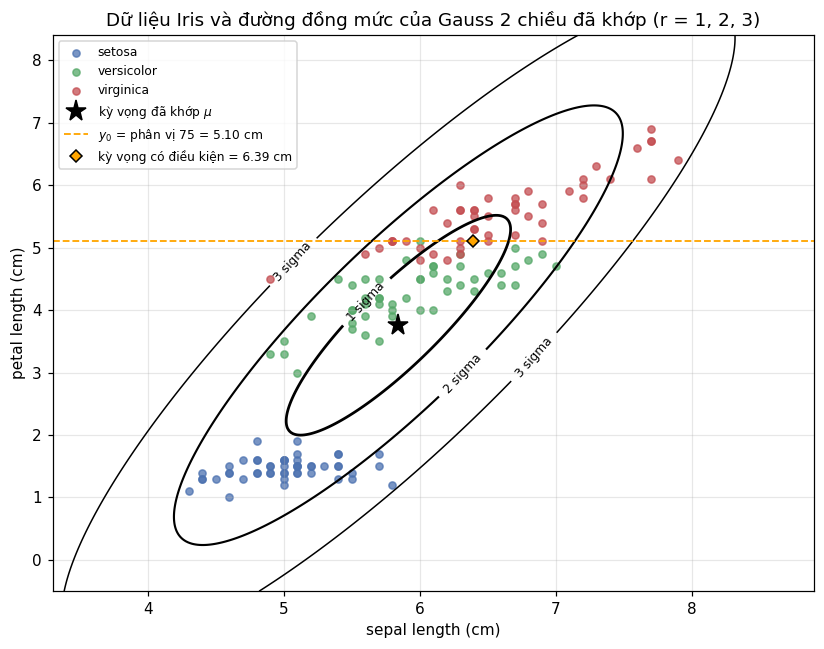

In [18]:
# === NHIỆM VỤ B4 ===
gx = np.linspace(x.min() - 1, x.max() + 1, 400)
gy = np.linspace(y.min() - 1.5, y.max() + 1.5, 400)
GX, GY = np.meshgrid(gx, gy)
pdf_grid = mvn_pdf(np.column_stack([GX.ravel(), GY.ravel()]), mu, Sigma).reshape(GX.shape)
p_max = 1 / (2 * np.pi * math.sqrt(np.linalg.det(Sigma)))
levels = [p_max * math.exp(-r ** 2 / 2) for r in (3, 2, 1)]          # tăng dần

fig, ax = plt.subplots(figsize=(7.6, 6))
colors = {"setosa": "#4C72B0", "versicolor": "#55A868", "virginica": "#C44E52"}
for sp, g in df.groupby("species"):
    key = str(sp).replace("Iris-", "")          # dùng được cho cả "setosa" và "Iris-setosa"
    ax.scatter(g[X_NAME], g[Y_NAME], s=22, alpha=.75,
               color=colors[key], label=key)
cs = ax.contour(GX, GY, pdf_grid, levels=levels, colors="black", linewidths=[1, 1.4, 1.8])
fmt = {lv: f"{r} sigma" for lv, r in zip(levels, (3, 2, 1))}
ax.clabel(cs, fmt=fmt, fontsize=8)
ax.plot(*mu, "k*", ms=14, label="kỳ vọng đã khớp $\\mu$")
ax.axhline(y0, color="orange", ls="--", lw=1.2, label=f"$y_0$ = phân vị 75 = {y0:.2f} cm")
ax.plot(mu_cond, y0, "D", color="orange", mec="k", label=f"kỳ vọng có điều kiện = {mu_cond:.2f} cm")
ax.set_xlabel(X_NAME); ax.set_ylabel(Y_NAME)
ax.set_title("Dữ liệu Iris và đường đồng mức của Gauss 2 chiều đã khớp (r = 1, 2, 3)")
ax.legend(loc="upper left", fontsize=8); plt.tight_layout(); plt.show()


In [19]:
# Đánh giá định lượng độ khớp: khoảng cách Mahalanobis
d2 = np.einsum("ni,ij,nj->n", Dc, np.linalg.inv(Sigma), Dc)
cov_tbl = pd.DataFrame({
    "r": [1, 2, 3],
    "lý thuyết 1 - exp(-r^2/2)": [1 - math.exp(-r ** 2 / 2) for r in (1, 2, 3)],
    "tỉ lệ quan sát bên trong": [(d2 <= r ** 2).mean() for r in (1, 2, 3)],
}).set_index("r")
cov_tbl["chênh lệch"] = cov_tbl["tỉ lệ quan sát bên trong"] - cov_tbl["lý thuyết 1 - exp(-r^2/2)"]
print(cov_tbl.round(4))

def skew_kurt(t):
    z = (t - t.mean()) / t.std()
    return (z ** 3).mean(), (z ** 4).mean() - 3
for name, t in ((X_NAME, x), (Y_NAME, y)):
    sk, ku = skew_kurt(t)
    print(f"{name:20s} độ lệch (skewness) = {sk:+.3f},  độ nhọn dư (excess kurtosis) = {ku:+.3f}   (Gauss: 0 và 0)")


   lý thuyết 1 - exp(-r^2/2)  tỉ lệ quan sát bên trong  chênh lệch
r                                                                 
1                     0.3935                    0.2600     -0.1335
2                     0.8647                    0.9200      0.0553
3                     0.9889                    0.9933      0.0044
sepal length (cm)    độ lệch (skewness) = +0.312,  độ nhọn dư (excess kurtosis) = -0.574   (Gauss: 0 và 0)
petal length (cm)    độ lệch (skewness) = -0.272,  độ nhọn dư (excess kurtosis) = -1.396   (Gauss: 0 và 0)


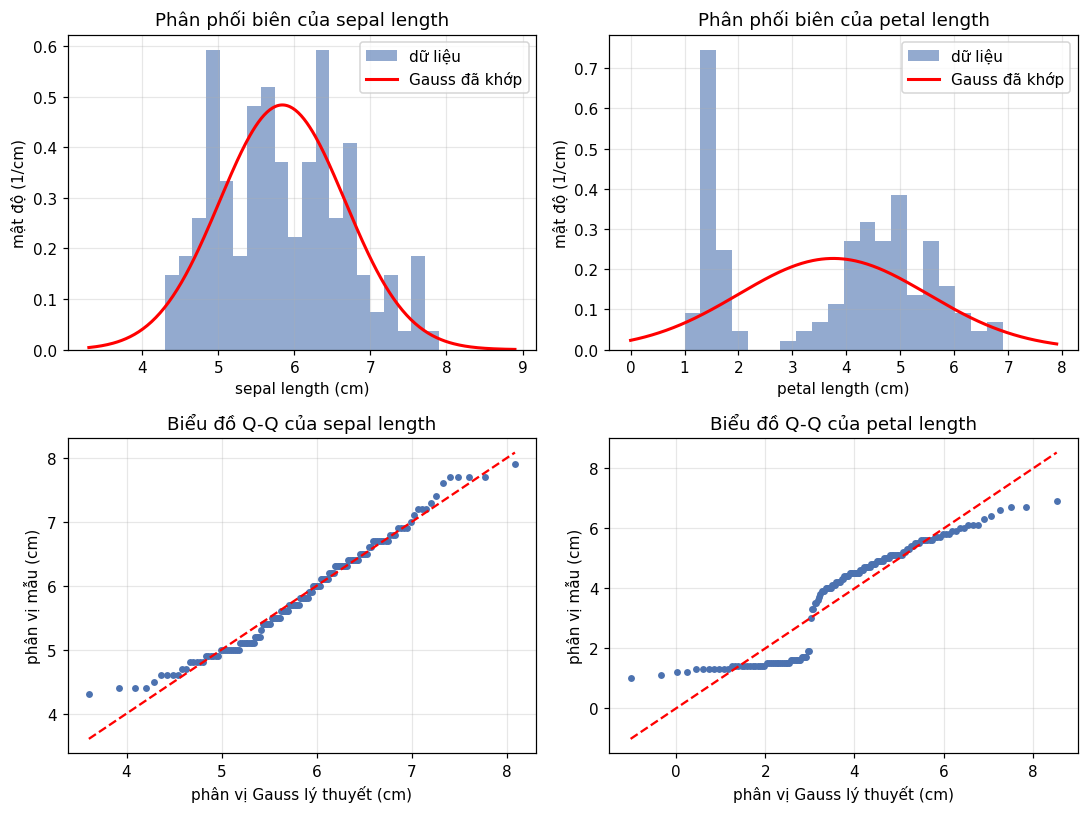

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
for j, (name, t, m, v) in enumerate(((X_NAME, x, mu_x, Sxx), (Y_NAME, y, mu_y, Syy))):
    ax = axes[0, j]
    ax.hist(t, bins=20, density=True, alpha=.6, color="#4C72B0", label="dữ liệu")
    gg = np.linspace(t.min() - 1, t.max() + 1, 300)
    ax.plot(gg, norm_pdf(gg, m, v), "r-", lw=2, label="Gauss đã khớp")
    ax.set_xlabel(name); ax.set_ylabel("mật độ (1/cm)"); ax.set_title(f"Phân phối biên của {name.split(' (')[0]}"); ax.legend()
    ax = axes[1, j]
    srt = np.sort(t); q = [NormalDist(m, math.sqrt(v)).inv_cdf((i + 0.5) / N) for i in range(N)]
    ax.plot(q, srt, "o", ms=3.5, color="#4C72B0"); ax.plot([q[0], q[-1]], [q[0], q[-1]], "r--")
    ax.set_xlabel(f"phân vị Gauss lý thuyết (cm)"); ax.set_ylabel(f"phân vị mẫu (cm)")
    ax.set_title(f"Biểu đồ Q-Q của {name.split(' (')[0]}")
plt.tight_layout(); plt.show()


**Nhận xét (độ phù hợp của giả thiết Gauss).**
* Các ellipse nắm bắt tốt **hướng và độ mạnh của tương quan**: trục chính nghiêng lên đúng như đám mây điểm, và kỳ vọng nằm đúng chỗ.
* Độ khớp chỉ ở mức **vừa phải**, vì dữ liệu là hỗn hợp của nhiều loài. Biểu đồ phân tán cho thấy hai nhóm: một cụm nhỏ, chặt (setosa) ở giá trị thấp và một nhóm lớn hơn, kéo dài ở giá trị cao, giữa hai nhóm có một **khoảng trống**. Một Gauss đơn đặt mật độ cao nhất đúng vào khoảng trống đó, trong khi dữ liệu có rất ít khối lượng ở đấy. Chiều dài đài hoa gần với Gauss (các điểm Q-Q gần đường thẳng, độ nhọn dư khoảng −0.6), nhưng **chiều dài cánh hoa rõ ràng có hai đỉnh (bimodal)** (một đỉnh nhọn quanh 1–2 cm, một khoảng trống, rồi một gò rộng quanh 4–6 cm), biểu đồ Q-Q của nó có dạng chữ S và độ nhọn dư khoảng −1.4.
* Bảng khoảng cách Mahalanobis cho kết quả định lượng: chỉ khoảng 26 % số điểm nằm trong ellipse 1σ (Gauss cho 39.3 %) trong khi khoảng 92 % nằm trong ellipse 2σ (Gauss: 86.5 %), và 99.3 % nằm trong 3σ (Gauss: 98.9 %). Quá ít điểm gần tâm và quá nhiều điểm ở "vai" là dấu hiệu của khoảng trống giữa các cụm, không phải của một đám mây Gauss.
* **Hệ quả với B3:** phân phối có điều kiện Gauss là một *bản tóm tắt tuyến tính* tốt ("chiều dài đài hoa tăng tuyến tính theo chiều dài cánh hoa với độ phân tán xấp xỉ không đổi"), nhưng phép kiểm tra thực nghiệm ở cuối B3 cho thấy một khác biệt nhỏ (kỳ vọng thực nghiệm của $X$ gần $y_0$ thấp hơn kỳ vọng có điều kiện Gauss khoảng 0.16 cm; phương sai 0.144 so với 0.164 cm², chỉ từ 21 quan sát), nhắc rằng dữ liệu không đồng thời Gauss một cách chính xác. Điều này dẫn đến các mô hình hỗn hợp (mixture) — chủ đề của B5.


### B5. Hỗn hợp hai phân phối Gauss 1 chiều (mixture) — làm tay

**Đề bài.** Với $p(x)=\pi\,\mathcal N(\mu_1,\sigma_1^2)+(1-\pi)\,\mathcal N(\mu_2,\sigma_2^2)$ với các tham số tự chọn, tính $E[X]$ và $V[X]$ bằng tay, kiểm tra bằng luật phương sai toàn phần (law of total variance) và giải thích vì sao $V[X]\neq\pi\sigma_1^2+(1-\pi)\sigma_2^2$.

**Tham số đã chọn (số tròn để phép tính trên giấy chính xác):**
$$\pi=0.4,\quad \mu_1=2,\ \sigma_1^2=1,\quad \mu_2=6,\ \sigma_2^2=4.$$
(Ý tưởng: một nhóm "thấp" và một nhóm "cao", giống hai cụm đã thấy ở B4. Hãy đổi các tham số trong ô lệnh nếu nhóm chọn giá trị khác.)

**Lời giải tay.** Đưa vào nhãn ẩn (latent label) $Z\in\{1,2\}$ với $P(Z=1)=\pi$.

*Kỳ vọng.* $E[X]=\pi\mu_1+(1-\pi)\mu_2=0.4\cdot2+0.6\cdot6=0.8+3.6=\mathbf{4.4}$.

*Phương sai qua moment bậc hai.* $E[X^2]=\pi(\sigma_1^2+\mu_1^2)+(1-\pi)(\sigma_2^2+\mu_2^2)=0.4(1+4)+0.6(4+36)=2+24=26$, nên
$V[X]=E[X^2]-E[X]^2=26-4.4^2=26-19.36=\mathbf{6.64}$.

*Luật phương sai toàn phần:* $V[X]=E\big[V[X\mid Z]\big]+V\big[E[X\mid Z]\big]$.
* $E[V[X\mid Z]]=\pi\sigma_1^2+(1-\pi)\sigma_2^2=0.4\cdot1+0.6\cdot4=2.8$ (độ phân tán trung bình **bên trong** các thành phần).
* $V[E[X\mid Z]]=\pi(\mu_1-E[X])^2+(1-\pi)(\mu_2-E[X])^2=0.4(2-4.4)^2+0.6(6-4.4)^2=0.4\cdot5.76+0.6\cdot2.56=2.304+1.536=3.84$ (độ phân tán của các kỳ vọng thành phần **giữa** các thành phần). Dạng đóng tương đương: $\pi(1-\pi)(\mu_1-\mu_2)^2=0.24\cdot16=3.84$.
* Tổng: $2.8+3.84=\mathbf{6.64}$ ✓ — trùng với cách đi qua moment bậc hai.

**Vì sao $V[X]\ne\pi\sigma_1^2+(1-\pi)\sigma_2^2$.** Trung bình có trọng số của các phương sai (2.8) chỉ là phần *trong từng thành phần* (within). Một hỗn hợp còn phân tán thêm vì các thành phần có tâm ở **những chỗ khác nhau**; điều đó thêm vào số hạng *giữa các thành phần* (between) $\pi(1-\pi)(\mu_1-\mu_2)^2\ge0$. Hai đại lượng chỉ bằng nhau khi $\mu_1=\mu_2$ (hoặc $\pi\in\{0,1\}$). Phương sai của một hỗn hợp không phải là hỗn hợp của các phương sai, trong khi *kỳ vọng* của một hỗn hợp *chính là* hỗn hợp của các kỳ vọng.


In [21]:
# === NHIỆM VỤ B5 ===
# các tham số do nhóm chọn
pi_, m1, v1, m2, v2 = 0.4, 2.0, 1.0, 6.0, 4.0

# --- công thức làm tay, từng bước ---
E_hand   = pi_ * m1 + (1 - pi_) * m2
EX2_hand = pi_ * (v1 + m1**2) + (1 - pi_) * (v2 + m2**2)
V_hand   = EX2_hand - E_hand**2
within   = pi_ * v1 + (1 - pi_) * v2                                    # E[V[X|Z]]
between  = pi_ * (m1 - E_hand)**2 + (1 - pi_) * (m2 - E_hand)**2        # V[E[X|Z]]
between_closed = pi_ * (1 - pi_) * (m1 - m2)**2
print(f"E[X]            = {E_hand:.4f}")
print(f"E[X^2]          = {EX2_hand:.4f}  ->  V[X] = E[X^2] - E[X]^2 = {V_hand:.4f}")
print(f"trong nhóm  E[V[X|Z]] = {within:.4f}")
print(f"giữa các nhóm V[E[X|Z]] = {between:.4f}   (dạng đóng pi(1-pi)(mu1-mu2)^2 = {between_closed:.4f})")
print(f"trong + giữa      = {within + between:.4f}   so với   V[X] = {V_hand:.4f}   ->  bằng nhau: {math.isclose(within + between, V_hand)}")
print(f"trung bình có trọng số 'ngây thơ' của các phương sai = {within:.4f}  ->  còn thiếu {V_hand - within:.4f} (= số hạng giữa các nhóm)")

# --- các kiểm tra số độc lập ---
def mix_pdf(t):
    return pi_ * norm_pdf(t, m1, v1) + (1 - pi_) * norm_pdf(t, m2, v2)

tt = np.linspace(-15, 25, 400_001)
dens = mix_pdf(tt)
area = trapezoid(dens, tt)
E_num = trapezoid(tt * dens, tt)
V_num = trapezoid((tt - E_num) ** 2 * dens, tt)

rng = np.random.default_rng(7)
M = 2_000_000
z = rng.random(M) < pi_
s = np.where(z, rng.normal(m1, math.sqrt(v1), M), rng.normal(m2, math.sqrt(v2), M))

chk = pd.DataFrame({"E[X]": [E_hand, E_num, s.mean()], "V[X]": [V_hand, V_num, s.var()]},
                   index=["làm tay", "tích phân số của hàm mật độ", f"Monte Carlo ({M:,} mẫu)"])
print("\nmật độ có tích phân bằng", round(area, 8))
print(chk.round(4).to_string())


E[X]            = 4.4000
E[X^2]          = 26.0000  ->  V[X] = E[X^2] - E[X]^2 = 6.6400
trong nhóm  E[V[X|Z]] = 2.8000
giữa các nhóm V[E[X|Z]] = 3.8400   (dạng đóng pi(1-pi)(mu1-mu2)^2 = 3.8400)
trong + giữa      = 6.6400   so với   V[X] = 6.6400   ->  bằng nhau: True
trung bình có trọng số 'ngây thơ' của các phương sai = 2.8000  ->  còn thiếu 3.8400 (= số hạng giữa các nhóm)

mật độ có tích phân bằng 1.0
                               E[X]    V[X]
làm tay                      4.4000  6.6400
tích phân số của hàm mật độ  4.4000  6.6400
Monte Carlo (2,000,000 mẫu)  4.3997  6.6341


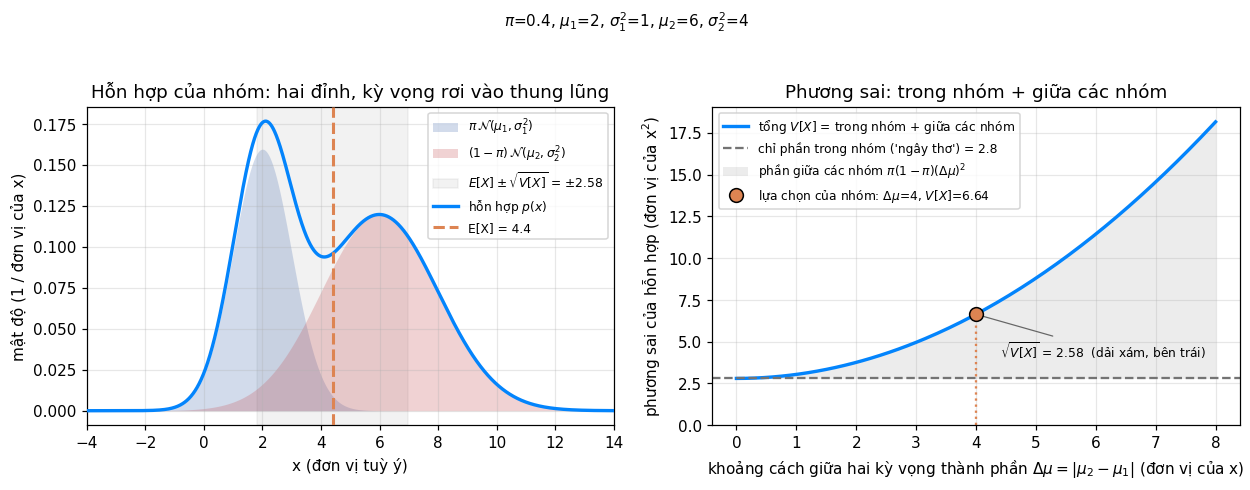

In [22]:
ORANGE = "#DD8452"
BLUE, RED = "#4C72B0", "#C44E52"
MIX = "#0384fc"


fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
sd = math.sqrt(V_hand)

# ---------------- Trái: hỗn hợp mà nhóm đã chọn ----------------
ax = axes[0]
c1 = pi_ * norm_pdf(tt, m1, v1)
c2 = (1 - pi_) * norm_pdf(tt, m2, v2)

ax.fill_between(tt, c1, color=BLUE, alpha=.25, lw=0,
                label=r"$\pi\,\mathcal{N}(\mu_1,\sigma_1^2)$")
ax.fill_between(tt, c2, color=RED, alpha=.25, lw=0,
                label=r"$(1-\pi)\,\mathcal{N}(\mu_2,\sigma_2^2)$")
ax.axvspan(E_hand - sd, E_hand + sd, color="0.5", alpha=.10, zorder=0,
           label=rf"$E[X]\pm\sqrt{{V[X]}}$ = ±{sd:.2f}")
ax.plot(tt, mix_pdf(tt), color=MIX, lw=2.2, zorder=5, label="hỗn hợp $p(x)$")
ax.axvline(E_hand, color=ORANGE, lw=2, ls="--", zorder=6, label=f"E[X] = {E_hand:.1f}")

ax.set_xlim(-4, 14)
ax.set_xlabel("x (đơn vị tuỳ ý)")
ax.set_ylabel("mật độ (1 / đơn vị của x)")
ax.set_title("Hỗn hợp của nhóm: hai đỉnh, kỳ vọng rơi vào thung lũng")
ax.legend(fontsize=8, loc="upper right")

# ---------------- Phải: phương sai của nó được tạo thành như thế nào ----------------
ax = axes[1]
dmu = np.linspace(0, 8, 161)
V_curve = within + pi_ * (1 - pi_) * dmu ** 2

ax.plot(dmu, V_curve, color=MIX, lw=2.2, label=r"tổng $V[X]$ = trong nhóm + giữa các nhóm")
ax.axhline(within, color="0.45", ls="--", lw=1.5,
           label=rf"chỉ phần trong nhóm ('ngây thơ') = {within:.1f}")
ax.fill_between(dmu, within, V_curve, color="0.5", alpha=.15, lw=0,
                label=r"phần giữa các nhóm $\pi(1-\pi)(\Delta\mu)^2$")

# lựa chọn của nhóm, cùng màu cam với E[X] ở hình trái
dm = abs(m2 - m1)
ax.vlines(dm, 0, V_hand, color=ORANGE, ls=":", lw=1.5)
ax.plot([dm], [V_hand], "o", color=ORANGE, mec="k", ms=9, zorder=6,
        label=rf"lựa chọn của nhóm: $\Delta\mu$={dm:.0f}, $V[X]$={V_hand:.2f}")
ax.annotate(rf"$\sqrt{{V[X]}}$ = {sd:.2f}  (dải xám, bên trái)",
            xy=(dm, V_hand), xytext=(dm + 0.4, V_hand - 2.6), fontsize=8,
            arrowprops=dict(arrowstyle="-", color="0.4", lw=.8))

ax.set_ylim(bottom=0)
ax.set_xlabel(r"khoảng cách giữa hai kỳ vọng thành phần $\Delta\mu=|\mu_2-\mu_1|$ (đơn vị của x)")
ax.set_ylabel(r"phương sai của hỗn hợp (đơn vị của x$^2$)")
ax.set_title("Phương sai: trong nhóm + giữa các nhóm")
ax.legend(fontsize=8, loc="upper left")

fig.suptitle(rf"$\pi$={pi_}, $\mu_1$={m1:g}, $\sigma_1^2$={v1:g}, $\mu_2$={m2:g}, $\sigma_2^2$={v2:g}",
             fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


**Nhận xét.**
* Cách làm tay, tích phân số và Monte Carlo cho cùng $E[X]=4.4$ và $V[X]=6.64$ (các chữ số của Monte Carlo dao động nhẹ).
* Hình trái: hỗn hợp có hai đỉnh và kỳ vọng chung (4.4) nằm ở **thung lũng** giữa hai đỉnh, nơi có rất ít xác suất, giống như Gauss đơn ở B4 có đỉnh nằm ở khoảng trống giữa các cụm Iris. Hình phải: khi các kỳ vọng thành phần rời xa nhau, phương sai cứ tăng dần, trong khi trung bình có trọng số "ngây thơ" của các phương sai vẫn cố định ở 2.8.
* Mẹo khi học trên lớp: với hỗn hợp, luôn tính kỳ vọng trước, rồi dùng $V[X]=E[X^2]-E[X]^2$ hoặc "trong nhóm + giữa các nhóm" (within + between).


### Tóm tắt kết quả Nhiệm vụ B (cho báo cáo)


In [23]:
print(f"Đặc trưng: X = {X_NAME}, Y = {Y_NAME}; N = {N}; mẫu số hiệp phương sai = N")
print(f"B1  mu = ({mu_x:.4f}, {mu_y:.4f}) cm;  Sigma = [[{Sxx:.4f}, {Sxy:.4f}], [{Sxy:.4f}, {Syy:.4f}]] cm^2;  rho = {rho:.4f}")
print(f"B2  p(y) = N({mu_y:.4f} cm, {Syy:.4f} cm^2)  (đọc từ khối Sigma_yy; tích phân số cho kết quả khớp)")
print(f"B3  y0 = {y0:.4f} cm;  p(x | y0) = N({mu_cond_hand} cm, {var_cond_hand} cm^2) làm tay")
print(f"    chính xác: N({mu_cond:.4f}, {var_cond:.4f});  tỉ số phương sai {var_cond / Sxx:.4f} = 1 - rho^2  (< 1: ĐẠT)")
print(f"B4  độ phủ Mahalanobis (1,2,3 sigma): {cov_tbl['tỉ lệ quan sát bên trong'].round(3).tolist()} so với lý thuyết {cov_tbl.iloc[:, 0].round(3).tolist()}")
print(f"B5  pi={pi_}, μ=({m1},{m2}), phương sai=({v1},{v2}):  E[X] = {E_hand:.2f},  V[X] = {V_hand:.2f} = {within:.2f} (trong nhóm) + {between:.2f} (giữa các nhóm)")


Đặc trưng: X = sepal length (cm), Y = petal length (cm); N = 150; mẫu số hiệp phương sai = N
B1  mu = (5.8433, 3.7580) cm;  Sigma = [[0.6811, 1.2658], [1.2658, 3.0955]] cm^2;  rho = 0.8718
B2  p(y) = N(3.7580 cm, 3.0955 cm^2)  (đọc từ khối Sigma_yy; tích phân số cho kết quả khớp)
B3  y0 = 5.1000 cm;  p(x | y0) = N(6.392 cm, 0.1635 cm^2) làm tay
    chính xác: N(6.3921, 0.1635);  tỉ số phương sai 0.2400 = 1 - rho^2  (< 1: ĐẠT)
B4  độ phủ Mahalanobis (1,2,3 sigma): [0.26, 0.92, 0.993] so với lý thuyết [0.393, 0.865, 0.989]
B5  pi=0.4, μ=(2.0,6.0), phương sai=(1.0,4.0):  E[X] = 4.40,  V[X] = 6.64 = 2.80 (trong nhóm) + 3.84 (giữa các nhóm)


---
# NHIỆM VỤ C — CHƯƠNG 7: HẠ GRADIENT

**MAI391 — Toán cho Học máy**  
Dữ liệu: Iris (tiếp nối Assignment 1)  
Đặc trưng: sepal length ($x_1$), sepal width ($x_2$) → dự đoán petal length ($y$)  
Dữ liệu đã chuẩn hoá mean=0, std=1.

$$
L(w_1,w_2)=\frac{1}{N}\sum_{n=1}^{N}(w_1 x_{n1}+w_2 x_{n2}-y_n)^2
$$

**Lưu ý:** Nhiệm vụ A, B (phân phối) **không ảnh hưởng** trực tiếp đến C. C tối ưu cùng hàm mất mát tuyến tính như Assignment 1.

In [24]:
# === NHIỆM VỤ C: nạp dữ liệu & chuẩn hoá ===
np.set_printoptions(precision=8, suppress=False, linewidth=75)   # trả về cấu hình in mặc định (Nhiệm vụ B đã đổi)
# Nhiệm vụ C dùng tệp iris.data gốc của UCI (khác bezdekIris.data ở mẫu 35 và 38)
DATA_PATH_C = next((Path(p) for p in ('iris.data', 'data/iris.data', 'iris/iris.data') if Path(p).exists()), None)
if DATA_PATH_C is None:   # không thấy tệp: dựng lại từ bezdekIris.data bằng hai dòng khác biệt đã biết
    _lines = [l for l in Path(DATA_PATH).read_text().splitlines() if l.strip()]
    _lines[34] = '4.9,3.1,1.5,0.1,Iris-setosa'; _lines[37] = '4.9,3.1,1.5,0.1,Iris-setosa'
    Path('iris.data').write_text('\n'.join(_lines) + '\n'); DATA_PATH_C = Path('iris.data')
print('Dữ liệu Nhiệm vụ C:', DATA_PATH_C)
cols = ["sepal_length", "sepal_width", "petal_length", "petal_width", "class"]
df = pd.read_csv(DATA_PATH_C, header=None, names=cols)

X1 = df["sepal_length"].values.astype(float)
X2 = df["sepal_width"].values.astype(float)
Y  = df["petal_length"].values.astype(float)

X1 = (X1 - X1.mean()) / X1.std()
X2 = (X2 - X2.mean()) / X2.std()
Y  = (Y  - Y.mean())  / Y.std()

X = np.column_stack([X1, X2])  
N = len(Y)
print(f"N = {N}, X shape = {X.shape}")
print(f"mean X1={X1.mean():.2e}, mean X2={X2.mean():.2e}, mean Y={Y.mean():.2e}")

Dữ liệu Nhiệm vụ C: iris.data
N = 150, X shape = (150, 2)
mean X1=-4.74e-16, mean X2=-6.63e-16, mean Y=3.32e-16


In [25]:
# === NHIỆM VỤ C: hàm mất mát và gradient ===
def loss(w, X, Y):
    """L(w) = (1/N) ||Xw - y||^2"""
    r = X @ w - Y
    return np.mean(r ** 2)

def grad(w, X, Y):
    """∇L = (2/N) X^T (Xw - y)  — dạng cột (2,)"""
    r = X @ w - Y
    return (2.0 / len(Y)) * (X.T @ r)

w0 = np.zeros(2)
print("L(0) =", loss(w0, X, Y))
print("∇L(0) =", grad(w0, X, Y))

L(0) = 0.9999999999999997
∇L(0) = [-1.74350831  0.84103219]


### C1. Cài đặt hạ gradient từ đầu

Hàm `gradient_descent(gamma, n_iters, w_init)` trả về:
- `W`: mảng `(n_iters+1, 2)` — dãy $\{w^{(t)}\}$
- `L_hist`: mảng `(n_iters+1,)` — dãy $\{L(w^{(t)})\}$

Cập nhật:
$$
w^{(t+1)} = w^{(t)} - \gamma \, \nabla L(w^{(t)})
$$

In [26]:
# === NHIỆM VỤ C1 ===
def gradient_descent(gamma, n_iters, w_init, X=X, Y=Y):
    """Hạ gradient thuần (không quán tính)."""
    w = np.array(w_init, dtype=float).copy()
    W = [w.copy()]
    L_hist = [loss(w, X, Y)]
    for t in range(n_iters):
        g = grad(w, X, Y)
        w = w - gamma * g
        W.append(w.copy())
        L_hist.append(loss(w, X, Y))
    return np.array(W), np.array(L_hist)

W_test, L_test = gradient_descent(0.1, 50, [0.0, 0.0])
print("Sau 50 bước γ=0.1: w =", W_test[-1], ", L =", L_test[-1])

Sau 50 bước γ=0.1: w = [ 0.83574367 -0.32912154] , L = 0.13302710585623123


### C2. Bốn bước học γ ∈ {0.001, 0.01, 0.1, 1}

Cùng điểm xuất phát $w^{(0)}=(0,0)$. Vẽ $L(w^{(t)})$ theo $t$ (trục tung log).

γ=0.001 | L cuối=4.986058e-01 | w cuối=[ 0.28489178 -0.13293401]
γ=0.010 | L cuối=1.332086e-01 | w cuối=[ 0.82224864 -0.3295167 ]
γ=0.100 | L cuối=1.330271e-01 | w cuối=[ 0.83575968 -0.32910969]
γ=1.000 | L cuối=1.741056e+34 | w cuối=[-8.85836084e+16  8.85836084e+16]


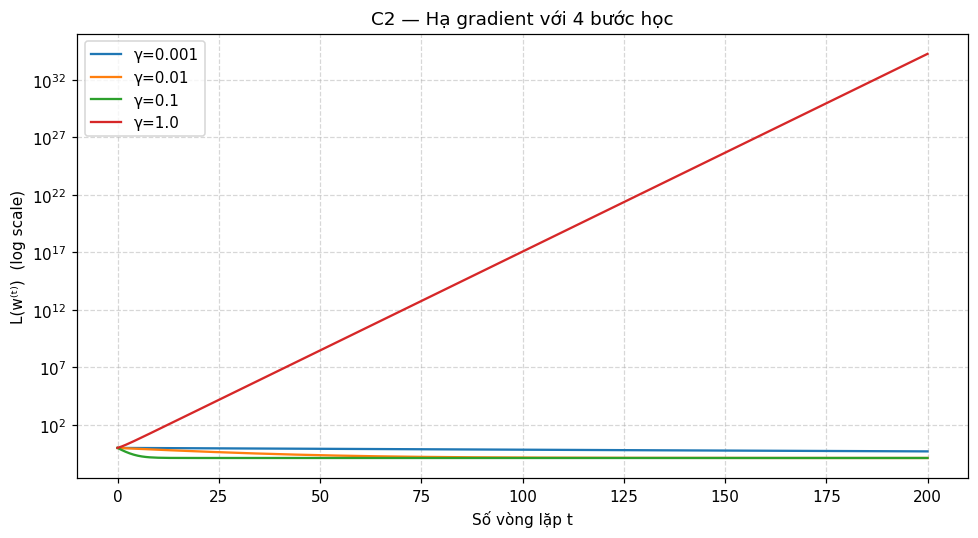

In [27]:
# === NHIỆM VỤ C2 ===
gammas = [0.001, 0.01, 0.1, 1.0]
n_iters = 200
w_init = np.array([0.0, 0.0])

results = {}
for g in gammas:
    W, Lh = gradient_descent(g, n_iters, w_init)
    results[g] = (W, Lh)
    print(f"γ={g:5.3f} | L cuối={Lh[-1]:.6e} | w cuối={W[-1]}")

plt.figure(figsize=(9, 5))
for g in gammas:
    _, Lh = results[g]
    L_plot = np.maximum(Lh, 1e-16)
    plt.semilogy(L_plot, label=f"γ={g}")
plt.xlabel("Số vòng lặp t")
plt.ylabel("L(w⁽ᵗ⁾)  (log scale)")
plt.title("C2 — Hạ gradient với 4 bước học")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

#### Nhận xét hiện tượng (điền vào báo cáo)

| γ | Hiện tượng |
|---|------------|
| 0.001 | Hội tụ rất chậm, L giảm đều nhưng sau 200 bước vẫn còn cao |
| 0.01 | Hội tụ ổn định, chậm vừa phải |
| 0.1 | Hội tụ nhanh, mượt |
| 1.0 | **Phân kỳ** — L tăng vọt (γ quá lớn so với 2/λ_max) |

### C3. Dạng toàn phương và điều kiện hội tụ

Viết
$$
L(w)=\frac12 w^\top Q w + c^\top w + \mathrm{const}
$$

Với $X\in\mathbb{R}^{N\times 2}$:
$$
L=\frac1N\|Xw-y\|^2
=\frac1N\bigl(w^\top X^\top X w - 2y^\top X w + y^\top y\bigr)
$$
Đối chiếu hệ số của $w^\top(\cdot)w$:
$$
\frac12 Q = \frac1N X^\top X \quad\Rightarrow\quad Q=\frac2N X^\top X
$$
$$
c=-\frac2N X^\top y,\qquad
\mathrm{const}=\frac1N y^\top y
$$

Điều kiện hội tụ hạ gradient cho hàm toàn phương lồi:
$$
0 < \gamma < \frac{2}{\lambda_{\max}(Q)}
$$

In [28]:
# === NHIỆM VỤ C3 ===
Q = (2.0 / N) * (X.T @ X)
c = -(2.0 / N) * (X.T @ Y)
const = (1.0 / N) * (Y @ Y)

eigvals = np.linalg.eigvalsh(Q)
lam_max = eigvals.max()
lam_min = eigvals.min()
gamma_max = 2.0 / lam_max

print("Q =")
print(Q)
print(f"\nGiá trị riêng λ = {eigvals}")
print(f"λ_max = {lam_max:.6f}")
print(f"λ_min = {lam_min:.6f}")
print(f"\nĐiều kiện hội tụ: 0 < γ < 2/λ_max = {gamma_max:.6f}")
print("\nĐối chiếu C2:")
print("  γ=0.001, 0.01, 0.1  < 0.901  → hội tụ")
print("  γ=1.0             > 0.901  → phân kỳ (đúng với thí nghiệm)")

Q =
[[ 2.        -0.2187385]
 [-0.2187385  2.       ]]

Giá trị riêng λ = [1.7812615 2.2187385]
λ_max = 2.218738
λ_min = 1.781262

Điều kiện hội tụ: 0 < γ < 2/λ_max = 0.901413

Đối chiếu C2:
  γ=0.001, 0.01, 0.1  < 0.901  → hội tụ
  γ=1.0             > 0.901  → phân kỳ (đúng với thí nghiệm)


### C4. Hạ gradient có quán tính (momentum)

Cập nhật:
$$
\begin{aligned}
v^{(t+1)} &= \alpha\, v^{(t)} + \gamma\, \nabla L(w^{(t)})\\
w^{(t+1)} &= w^{(t)} - v^{(t+1)}
\end{aligned}
$$

Với $\alpha\in\{0,\,0.5,\,0.9\}$. So sánh số vòng lặp để $L$ xuống dưới ngưỡng cố định.

γ = 0.1, ngưỡng L < 0.05
     α |     số vòng đạt ngưỡng |       L cuối
--------------------------------------------------
   0.0 |                   None | 1.330271e-01
   0.5 |                   None | 1.330271e-01
   0.9 |                   None | 1.330271e-01


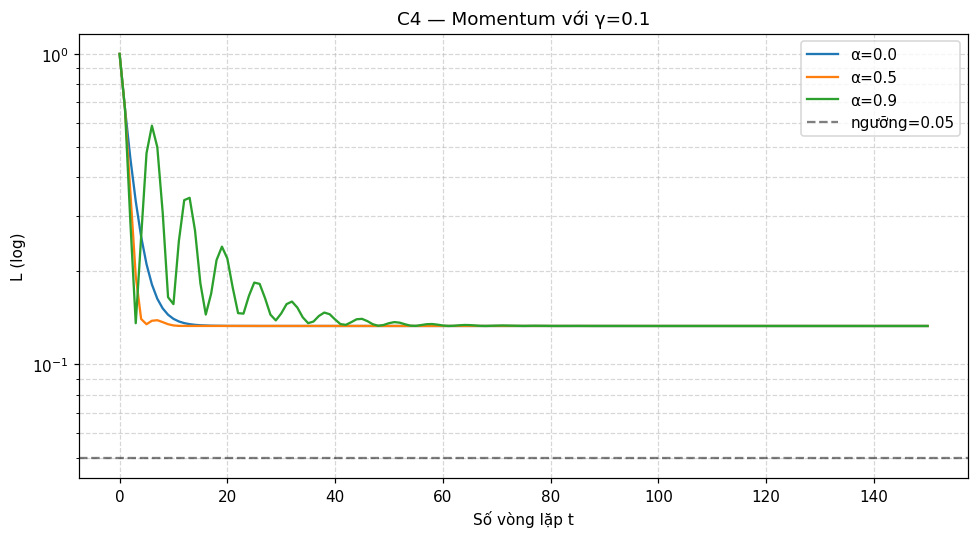

In [29]:
# === NHIỆM VỤ C4 ===
def gradient_descent_momentum(gamma, alpha, n_iters, w_init, X=X, Y=Y):
    """Hạ gradient + momentum."""
    w = np.array(w_init, dtype=float).copy()
    v = np.zeros_like(w)
    W = [w.copy()]
    L_hist = [loss(w, X, Y)]
    for t in range(n_iters):
        g = grad(w, X, Y)
        v = alpha * v + gamma * g
        w = w - v
        W.append(w.copy())
        L_hist.append(loss(w, X, Y))
    return np.array(W), np.array(L_hist)

def iters_to_threshold(L_hist, threshold):
    """Số vòng lặp đầu tiên L < threshold; None nếu không đạt."""
    for t, Lv in enumerate(L_hist):
        if Lv < threshold:
            return t
    return None

gamma_fixed = 0.1          
threshold = 0.05           
n_iters_long = 500
alphas = [0.0, 0.5, 0.9]

print(f"γ = {gamma_fixed}, ngưỡng L < {threshold}")
print(f"{'α':>6} | {'số vòng đạt ngưỡng':>22} | {'L cuối':>12}")
print("-" * 50)

table_rows = []
for a in alphas:
    _, Lh = gradient_descent_momentum(gamma_fixed, a, n_iters_long, w_init)
    t_star = iters_to_threshold(Lh, threshold)
    table_rows.append((a, t_star, Lh[-1]))
    print(f"{a:6.1f} | {str(t_star):>22} | {Lh[-1]:12.6e}")

# Vẽ so sánh
plt.figure(figsize=(9, 5))
for a in alphas:
    _, Lh = gradient_descent_momentum(gamma_fixed, a, 150, w_init)
    plt.semilogy(np.maximum(Lh, 1e-16), label=f"α={a}")
plt.axhline(threshold, color="k", ls="--", alpha=0.5, label=f"ngưỡng={threshold}")
plt.xlabel("Số vòng lặp t")
plt.ylabel("L (log)")
plt.title(f"C4 — Momentum với γ={gamma_fixed}")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

### C5. Hai vòng hạ gradient có quán tính trên 5 mẫu đầu (làm tay)

#### Dữ liệu 5 mẫu đầu (đã chuẩn hoá)

| $n$ | $x_{n1}$ | $x_{n2}$ | $y_n$ |
|-----|----------|----------|-------|
| 1 | −0.900681 | 1.032057 | −1.341272 |
| 2 | −1.143017 | −0.124958 | −1.341272 |
| 3 | −1.385353 | 0.337848 | −1.398138 |
| 4 | −1.506521 | 0.106445 | −1.284407 |
| 5 | −1.021849 | 1.263460 | −1.341272 |

Chọn $\gamma=0.1$, $\alpha=0.5$, $w^{(0)}=(0,0)$, $v^{(0)}=(0,0)$.

$N'=5$ (chỉ 5 mẫu). Gradient:
$$
\nabla L(w)=\frac{2}{5}X_{5}^\top(X_{5}w-y_{5})
$$

In [30]:
# === NHIỆM VỤ C5 ===
X5 = X[:5]
Y5 = Y[:5]
print("X5 =")
print(X5)
print("Y5 =", Y5)

gamma = 0.1
alpha = 0.5

w = np.array([0.0, 0.0])
v = np.array([0.0, 0.0])
print("\n=== t=0 ===")
print("w =", w, " L =", loss(w, X5, Y5))
g = grad(w, X5, Y5)
print("∇L =", g)

v = alpha * v + gamma * g
w = w - v
print("\n=== t=1 ===")
print("v =", v)
print("w =", w, " L =", loss(w, X5, Y5))
g = grad(w, X5, Y5)
print("∇L =", g)

v = alpha * v + gamma * g
w = w - v
print("\n=== t=2 ===")
print("v =", v)
print("w =", w, " L =", loss(w, X5, Y5))

W_m, L_m = gradient_descent_momentum(gamma, alpha, 2, [0.0, 0.0], X=X5, Y=Y5)
print("\n--- Đối chiếu chương trình ---")
print("W =")
print(W_m)
print("L =", L_m)

X5 =
[[-0.90068117  1.03205722]
 [-1.14301691 -0.1249576 ]
 [-1.38535265  0.33784833]
 [-1.50652052  0.10644536]
 [-1.02184904  1.26346019]]
Y5 = [-1.3412724  -1.3412724  -1.39813811 -1.2844067  -1.3412724 ]

=== t=0 ===
w = [0. 0.]  L = 1.8003051470862985
∇L = [-3.19345326  1.4081559 ]

=== t=1 ===
v = [-0.31934533  0.14081559]
w = [ 0.31934533 -0.14081559]  L = 0.7919194800447599
∇L = [-2.10205948  0.90461424]

=== t=2 ===
v = [-0.36987861  0.16086922]
w = [ 0.68922394 -0.30168481]  L = 0.14893314256827028

--- Đối chiếu chương trình ---
W =
[[ 0.          0.        ]
 [ 0.31934533 -0.14081559]
 [ 0.68922394 -0.30168481]]
L = [1.80030515 0.79191948 0.14893314]


#### Làm tay chi tiết (C5)

**Tại $w^{(0)}=(0,0)$:**

$$
r_n = 0 - y_n = -y_n
$$

$$
\nabla L
=\frac{2}{5}\sum_{n=1}^{5} r_n\begin{bmatrix}x_{n1}\\x_{n2}\end{bmatrix}
=\frac{2}{5}\sum_{n=1}^{5}(-y_n)\begin{bmatrix}x_{n1}\\x_{n2}\end{bmatrix}
$$

Tính từng thành phần (số từ bảng):

$$
\sum (-y_n)x_{n1}
= -\bigl[(-1.341272)(-0.900681)+\cdots\bigr]
$$

(Chạy cell trên để lấy số chính xác, rồi chép vào báo cáo.)

**Vòng 1:**
$$
v^{(1)}=0.5\cdot 0 + 0.1\cdot\nabla L(w^{(0)})=0.1\,\nabla L(0)
$$
$$
w^{(1)}=w^{(0)}-v^{(1)}
$$

**Vòng 2:** lặp lại với $\nabla L(w^{(1)})$.

Kết quả số từ code (đối chiếu):
- Cell C5 in ra $w^{(1)}, w^{(2)}$ và $L$ tương ứng.
- Chép đúng các số đó vào báo cáo phần làm tay.

### Tóm tắt số liệu quan trọng cho báo cáo (Nhiệm vụ C)

| Đại lượng | Giá trị |
|-----------|--------|
| $Q$ | $\begin{bmatrix}2 & -0.2187\\ -0.2187 & 2\end{bmatrix}$ |
| $\lambda(Q)$ | $\{1.7813,\, 2.2187\}$ |
| $2/\lambda_{\max}$ | $\approx 0.9014$ |
| $c$ | $[-1.7435,\, 0.8410]^\top$ |
| $L(0)$ | $1$ |

**Điều kiện hội tụ:** $0 < \gamma < 0.9014$  
→ Giải thích vì sao $\gamma=1$ phân kỳ ở C2.

**C5 — tham số đề xuất:** $\gamma=0.1$, $\alpha=0.5$, 5 mẫu đầu, $w^{(0)}=0$.

---
# NHIỆM VỤ D — CHƯƠNG 7: RÀNG BUỘC VÀ TÍNH LỒI

In [31]:
# === NHIỆM VỤ D: nạp dữ liệu & chuẩn bị ===
np.random.seed(42)
D = np.genfromtxt(DATA_PATH, delimiter=',', usecols=(0, 1, 2, 3))   # sl, sw, pl, pw
Z = (D - D.mean(axis=0)) / D.std(axis=0)
N = len(Z)
FEATURES, TARGET = [1, 2], 0          # x1 = sepal width, x2 = petal length, y = sepal length
X, y = Z[:, FEATURES], Z[:, TARGET]
L = lambda w: np.mean((X @ w - y) ** 2)

# dạng toàn phương L(w) = 1/2 w^T Q w + c^T w + const
Q = 2 / N * X.T @ X
c = -2 / N * X.T @ y
const = y @ y / N
one = np.ones(2)
print('Q =\n', Q, '\nc =', c, '\nconst =', const)
w_test = np.array([0.3, -0.7])
print('kiểm tra dạng toàn phương:', L(w_test), 0.5 * w_test @ Q @ w_test + c @ w_test + const)

Q =
 [[ 2.         -0.85688021]
 [-0.85688021  2.        ]] 
c = [ 0.23513957 -1.74350755] 
const = 1.0
kiểm tra dạng toàn phương: 3.050942000539844 3.050942000539844


### D1. Hàm Lagrange
$g(w)=w_1+w_2-1\le0$, $\ \mathfrak L(w,\lambda)=L(w)+\lambda(w_1+w_2-1)$, $\lambda\ge0$.

In [32]:
# === NHIỆM VỤ D1 ===
lagr = lambda w, lam: L(w) + lam * (one @ w - 1)
print('L(w,lambda) tại w=(0.3,-0.7), lambda=0.5:', lagr(w_test, 0.5))

L(w,lambda) tại w=(0.3,-0.7), lambda=0.5: 2.3509420005398445


### D2. Điều kiện dừng và nghiệm tối ưu

In [33]:
# === NHIỆM VỤ D2 ===
Qi = np.linalg.inv(Q)               # chỉ để kiểm tra; phần lõi dùng solve bên dưới
w_u = np.linalg.solve(Q, -c)        # nghiệm không ràng buộc  w_u = -Q^{-1} c
print('w_u =', w_u, ' tổng =', w_u.sum(), ' -> vi phạm ràng buộc?', w_u.sum() > 1)
a = one @ np.linalg.solve(Q, one)   # 1^T Q^{-1} 1
lam = (one @ w_u - 1) / a           # từ ràng buộc hoạt động  1^T w(lambda) = 1
w_star = w_u - lam * np.linalg.solve(Q, one)
print('1^T Q^-1 1 =', a); print('lambda* =', lam); print('w* =', w_star, ' tổng =', w_star.sum())
print('lambda >= 0:', lam >= 0, '| g(w*) =', one @ w_star - 1, '| lambda*g(w*) =', lam * (one @ w_star - 1))
grad = Q @ w_star + c + lam * one
print('grad_w Lagrange tại (w*,lambda*) =', grad)
print('L(w_u) =', L(w_u), '| L(w*) =', L(w_star))

w_u = [0.31346429 1.00605445]  tổng = 1.319518737174895  -> vi phạm ràng buộc? True
1^T Q^-1 1 = 1.749597911919123
lambda* = 0.18262409608412083
w* = [0.15370492 0.84629508]  tổng = 0.9999999999999999
lambda >= 0: True | g(w*) = -1.1102230246251565e-16 | lambda*g(w*) = -2.0275347632394784e-17
grad_w Lagrange tại (w*,lambda*) = [ 8.32667268e-17 -3.88578059e-16]
L(w_u) = 0.15982216457377973 | L(w*) = 0.18899807485303224


In [34]:
# Kiểm tra độc lập: (i) tham số hoá đường w1+w2=1, (ii) hạ gradient chiếu
ts = np.linspace(-1, 2, 300001); W = np.c_[ts, 1 - ts]
vals = np.mean((W @ X.T - y) ** 2, axis=1)
print('(i)  quét trên đường w1+w2=1: w =', W[vals.argmin()], ' L =', vals.min())
w = np.zeros(2); step = 1 / np.linalg.eigvalsh(Q).max()
for _ in range(20000):
    w = w - step * (Q @ w + c)
    if one @ w > 1: w = w - (one @ w - 1) / 2 * one     # chiếu lên nửa mặt phẳng w1+w2<=1
print('(ii) hạ gradient chiếu:      w =', w, ' L =', L(w))

(i)  quét trên đường w1+w2=1: w = [0.1537 0.8463]  L = 0.18899807492219087
(ii) hạ gradient chiếu:      w = [0.15370492 0.84629508]  L = 0.18899807485303224


### D3. Tính lồi

In [35]:
# === NHIỆM VỤ D3 ===
ev = np.linalg.eigvalsh(Q)
print('giá trị riêng của Hesse Q =', ev, '-> xác định dương:', (ev > 0).all())
# tập chấp nhận được là nửa mặt phẳng: kiểm tra tổ hợp lồi ngẫu nhiên
rng = np.random.default_rng(42); ok = True
for _ in range(10000):
    p = rng.uniform(-5, 5, 2); q = rng.uniform(-5, 5, 2)
    if p.sum() <= 1 and q.sum() <= 1:
        t = rng.uniform(); ok &= (t * p + (1 - t) * q).sum() <= 1 + 1e-12
print('tổ hợp lồi của hai điểm chấp nhận được luôn chấp nhận được:', ok)
print('điều kiện Slater: g(0) =', one @ np.zeros(2) - 1, '< 0')

giá trị riêng của Hesse Q = [1.14311979 2.85688021] -> xác định dương: True


tổ hợp lồi của hai điểm chấp nhận được luôn chấp nhận được: True
điều kiện Slater: g(0) = -1.0 < 0


### D4. Bài toán đối ngẫu

In [36]:
# === NHIỆM VỤ D4 ===
dual = lambda l: const - 0.5 * (c + l * one) @ np.linalg.solve(Q, c + l * one) - l
cQc = c @ np.linalg.solve(Q, c); oQc = one @ np.linalg.solve(Q, c)
print('D(lambda) = %.4f + %.4f*lambda - %.4f*lambda^2' % (const - 0.5 * cQc, -(oQc + 1), 0.5 * a))
lam_dual = -(oQc + 1) / a
print('lambda* từ D\'(lambda)=0:', lam_dual, '(trùng lambda* ở D2:', np.isclose(lam_dual, lam), ')')
ls = np.linspace(0, 2, 200001); print('cực đại đối ngẫu quét lưới:', max(dual(t) for t in ls))
p_star, d_star = L(w_star), dual(lam)
print('giá trị gốc p* = %.10f | giá trị đối ngẫu d* = %.10f | khe hở = %.2e' % (p_star, d_star, p_star - d_star))
print('đối ngẫu yếu D(lambda) <= p*:', all(dual(t) <= p_star + 1e-12 for t in ls))

D(lambda) = 0.1598 + 0.3195*lambda - 0.8748*lambda^2
lambda* từ D'(lambda)=0: 0.18262409608412083 (trùng lambda* ở D2: True )


cực đại đối ngẫu quét lưới: 0.18899807483835496
giá trị gốc p* = 0.1889980749 | giá trị đối ngẫu d* = 0.1889980749 | khe hở = -1.39e-16


đối ngẫu yếu D(lambda) <= p*: True


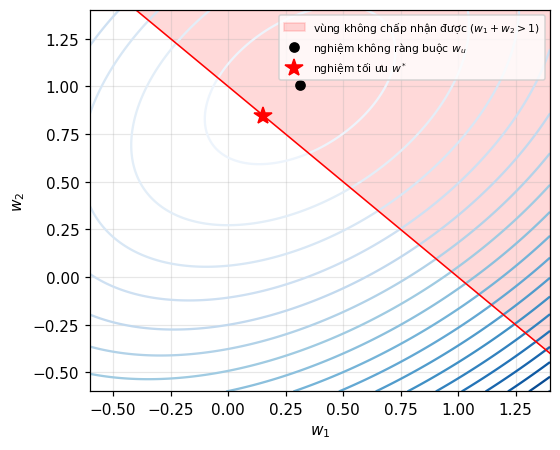

In [37]:
gx = np.linspace(-0.6, 1.4, 300); G1, G2 = np.meshgrid(gx, gx)
Lg = np.array([[L(np.array([a1, a2])) for a1 in gx] for a2 in gx])
plt.figure(figsize=(5.2, 4.2)); plt.contour(G1, G2, Lg, 20, cmap='Blues')
plt.fill_between(gx, 1 - gx, 1.4, alpha=0.15, color='red', label='vùng không chấp nhận được ($w_1+w_2>1$)')
plt.plot(gx, 1 - gx, 'r', lw=1)
plt.plot(*w_u, 'ko', label='nghiệm không ràng buộc $w_u$'); plt.plot(*w_star, 'r*', ms=12, label='nghiệm tối ưu $w^*$')
plt.xlabel('$w_1$'); plt.ylabel('$w_2$'); plt.xlim(-0.6, 1.4); plt.ylim(-0.6, 1.4); plt.legend(fontsize=7); plt.tight_layout(); plt.show()